# Етап 3: Transformers / Multimodal (CLIP ViT-B/32)

**Задача:** класифікація 27 стилів образотворчого мистецтва на датасеті WikiArt.

На цьому етапі досліджуємо мультимодальну модель **OpenAI CLIP (ViT-B/32)** —
`openai/clip-vit-base-patch32` з бібліотеки Hugging Face `transformers`.


In [1]:
try:
    import transformers
except ImportError:
    import sys
    import subprocess

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers"])
    import transformers

print(f"transformers: {transformers.__version__}")


d:\AI_lab1\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers: 5.21.0


In [2]:
import os
import time
import random
import tracemalloc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
import torchvision.datasets as datasets
from torch.utils.data import DataLoader, Subset
from tqdm import tqdm
from sklearn.metrics import (
    accuracy_score,
    top_k_accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
)
from transformers import CLIPModel, CLIPProcessor

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42


def set_seed(seed=SEED):
    # Фіксуємо всі джерела випадковості
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"

print(f"PyTorch: {torch.__version__}")
print(f"Device:  {device}")
if USE_AMP:
    props = torch.cuda.get_device_properties(0)
    print(f"GPU:     {props.name} | VRAM: {props.total_memory / 2**30:.1f} GB")
else:
    print("CUDA не знайдено")


PyTorch: 2.6.0+cu124
Device:  cuda
GPU:     NVIDIA GeForce GTX 1650 | VRAM: 4.0 GB


## 1. Підготовка даних


In [3]:
DATA_DIR = "./data"
MODEL_NAME = "openai/clip-vit-base-patch32"
IMG_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 4
TRAIN_RATIO = 0.85

assert os.path.isdir(DATA_DIR), (
    f"Папку {DATA_DIR} не знайдено"
)

processor = CLIPProcessor.from_pretrained(MODEL_NAME)

image_mean = getattr(
    processor.image_processor, "image_mean", [0.48145466, 0.4578275, 0.40821073]
)
image_std = getattr(
    processor.image_processor, "image_std", [0.26862954, 0.26130258, 0.27577711]
)

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.85, 1.18)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean=image_mean, std=image_std),
])

val_tf = T.Compose([
    T.Resize(IMG_SIZE, interpolation=T.InterpolationMode.BICUBIC),
    T.CenterCrop(IMG_SIZE),
    T.ToTensor(),
    T.Normalize(mean=image_mean, std=image_std),
])

train_base = datasets.ImageFolder(DATA_DIR, transform=train_tf)
val_base = datasets.ImageFolder(DATA_DIR, transform=val_tf)

assert train_base.classes == val_base.classes, "Порядок класів у train/val не збігається"

class_names = [c.replace("_", " ") for c in train_base.classes]
prompt_class_names = [n.replace("Ukiyo e", "Ukiyo-e") for n in class_names]
num_classes = len(class_names)

g = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_base), generator=g).tolist()
n_train = int(TRAIN_RATIO * len(train_base))
train_idx = indices[:n_train]
val_idx = indices[n_train:]

train_dataset = Subset(train_base, train_idx)
val_dataset = Subset(val_base, val_idx)

loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=USE_AMP,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=2 if NUM_WORKERS > 0 else None,
)

train_loader = DataLoader(train_dataset, shuffle=True, drop_last=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)

print(f"Класів (стилів): {num_classes}")
print(f"Train: {len(train_dataset):>6} зображень | {len(train_loader)} батчів")
print(f"Val:   {len(val_dataset):>6} зображень | {len(val_loader)} батчів")
print(f"Класи: {', '.join(class_names)}")

Класів (стилів): 27
Train:  69227 зображень | 1081 батчів
Val:    12217 зображень | 191 батчів
Класи: Abstract Expressionism, Action painting, Analytical Cubism, Art Nouveau Modern, Baroque, Color Field Painting, Contemporary Realism, Cubism, Early Renaissance, Expressionism, Fauvism, High Renaissance, Impressionism, Mannerism Late Renaissance, Minimalism, Naive Art Primitivism, New Realism, Northern Renaissance, Pointillism, Pop Art, Post Impressionism, Realism, Rococo, Romanticism, Symbolism, Synthetic Cubism, Ukiyo e


Найменший клас: Action painting — 82 зображень
Найбільший клас: Impressionism — 11102 зображень
Дисбаланс: 135.4x


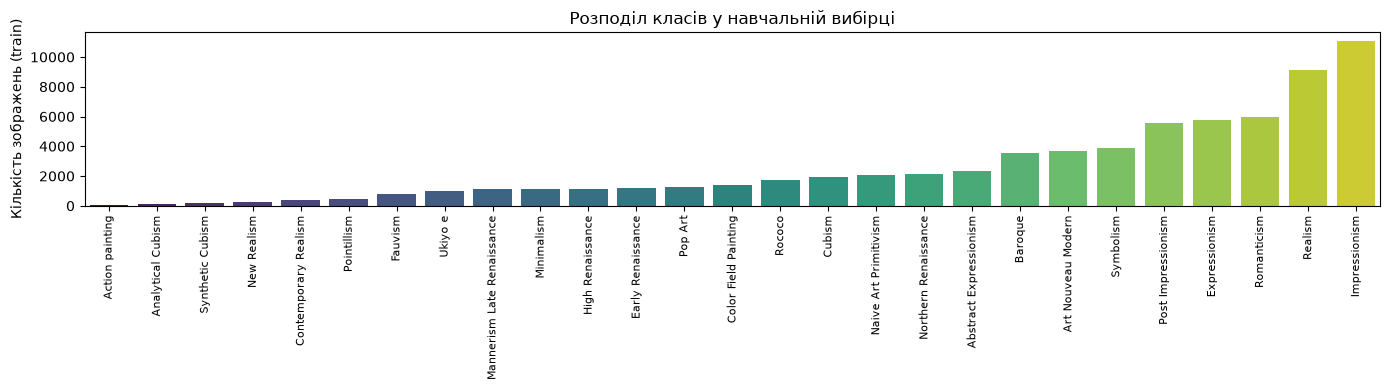

In [4]:
train_targets = np.array(train_base.targets)[train_idx]
counts = np.bincount(train_targets, minlength=num_classes)
order = np.argsort(counts)

print(f"Найменший клас: {class_names[order[0]]} — {counts[order[0]]} зображень")
print(f"Найбільший клас: {class_names[order[-1]]} — {counts[order[-1]]} зображень")
print(f"Дисбаланс: {counts.max() / counts.min():.1f}x")

plt.figure(figsize=(14, 4))
sns.barplot(
    x=[class_names[i] for i in order],
    y=counts[order],
    hue=[class_names[i] for i in order],
    palette="viridis",
    legend=False,
)
plt.xticks(rotation=90, fontsize=8)
plt.ylabel("Кількість зображень (train)")
plt.title("Розподіл класів у навчальній вибірці")
plt.tight_layout()
plt.show()

## 2. Zero-Shot класифікація CLIP

In [5]:
clip_model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
clip_model.eval()

total_params = sum(p.numel() for p in clip_model.parameters())
clip_param_size_mb = (
    sum(p.numel() * p.element_size() for p in clip_model.parameters()) / 2**20
)

print("CLIP ViT-B/32 завантажено")
print(f"Параметрів:        {total_params:,}")
print(f"Розмір параметрів: {clip_param_size_mb:.1f} MB")


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 19898.36it/s]


CLIP ViT-B/32 завантажено
Параметрів:        151,277,313
Розмір параметрів: 577.1 MB


In [6]:
PROMPT_TEMPLATES = [
    "a painting in the style of {}",
    "an artwork in the style of {}",
    "a {} painting",
    "a painting of {} style",
]

prompts = [
    tpl.format(style)
    for style in prompt_class_names
    for tpl in PROMPT_TEMPLATES
]

print("Приклади промптів:")
for p in prompts[: len(PROMPT_TEMPLATES)]:
    print("  •", p)

text_inputs = processor(
    text=prompts,
    return_tensors="pt",
    padding=True,
    truncation=True,
).to(device)

with torch.no_grad(), torch.cuda.amp.autocast(enabled=USE_AMP):
    text_out = clip_model.text_model(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs["attention_mask"],
    )
    text_features = clip_model.text_projection(text_out.pooler_output)

text_features = text_features.float()
text_features = text_features / text_features.norm(dim=-1, keepdim=True)
text_features = text_features.view(num_classes, len(PROMPT_TEMPLATES), -1).mean(dim=1)
text_features = text_features / text_features.norm(dim=-1, keepdim=True)

print(f"\nText embeddings: {tuple(text_features.shape)}")


Приклади промптів:
  • a painting in the style of Abstract Expressionism
  • an artwork in the style of Abstract Expressionism
  • a Abstract Expressionism painting
  • a painting of Abstract Expressionism style

Text embeddings: (27, 512)


In [7]:
@torch.no_grad()
def evaluate_zero_shot(model, loader, text_embeds):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []

    for images, targets in tqdm(loader, desc="Zero-Shot CLIP"):
        images = images.to(device, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            vision_out = model.vision_model(pixel_values=images)
            image_features = model.visual_projection(vision_out.pooler_output)

        image_features = image_features.float()
        image_features = image_features / image_features.norm(dim=-1, keepdim=True)

        logits = model.logit_scale.exp() * image_features @ text_embeds.t()
        probs = logits.softmax(dim=-1)

        all_probs.append(probs.cpu().numpy())
        all_preds.append(probs.argmax(dim=-1).cpu().numpy())
        all_targets.append(targets.numpy())

    all_probs = np.vstack(all_probs).astype(np.float32)
    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)

    top1 = accuracy_score(all_targets, all_preds) * 100
    top3 = (
        top_k_accuracy_score(
            all_targets, all_probs, k=3, labels=list(range(num_classes))
        )
        * 100
    )
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    bal_acc = balanced_accuracy_score(all_targets, all_preds) * 100

    return top1, top3, macro_f1, bal_acc, all_targets, all_preds, all_probs


In [8]:
tracemalloc.start()
t_zs = time.time()

zs_top1, zs_top3, zs_macro_f1, zs_bal_acc, zs_true, zs_pred, zs_probs = evaluate_zero_shot(
    clip_model, val_loader, text_features
)

zs_eval_time = time.time() - t_zs
_, zs_peak_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()
zs_ram_peak_mb = zs_peak_bytes / 2**20

print("\nZero-Shot результати:")
print(f"  Top-1 Accuracy:    {zs_top1:.2f}%")
print(f"  Top-3 Accuracy:    {zs_top3:.2f}%")
print(f"  Macro F1:          {zs_macro_f1:.4f}")
print(f"  Balanced Accuracy: {zs_bal_acc:.2f}%")
print(f"  Час оцінки:        {zs_eval_time:.1f} сек")
print(f"  Пік RAM:           {zs_ram_peak_mb:.1f} MB")

Zero-Shot CLIP: 100%|██████████| 191/191 [05:46<00:00,  1.81s/it]


Zero-Shot результати:
  Top-1 Accuracy:    26.14%
  Top-3 Accuracy:    53.38%
  Macro F1:          0.2258
  Balanced Accuracy: 33.38%
  Час оцінки:        346.6 сек
  Пік RAM:           6.2 MB


In [9]:
clip_model.eval()
sample_batch, _ = next(iter(val_loader))
sample_batch = sample_batch.to(device, non_blocking=True)

for _ in range(2):  # warm-up
    with torch.no_grad(), torch.cuda.amp.autocast(enabled=USE_AMP):
        _ = clip_model.vision_model(pixel_values=sample_batch)

if USE_AMP:
    torch.cuda.synchronize()

t0 = time.perf_counter()
with torch.no_grad(), torch.cuda.amp.autocast(enabled=USE_AMP):
    _ = clip_model.vision_model(pixel_values=sample_batch)
if USE_AMP:
    torch.cuda.synchronize()

zs_inference_ms = (time.perf_counter() - t0) * 1000.0 / len(sample_batch)
print(f"Zero-Shot inference: {zs_inference_ms:.4f} мс / зразок (batch={len(sample_batch)})")

zs_metrics = {
    "Model": "CLIP ViT-B/32 (Zero-Shot)",
    "Top1_Acc_%": round(zs_top1, 2),
    "Top3_Acc_%": round(zs_top3, 2),
    "Macro_F1": round(zs_macro_f1, 4),
    "Balanced_Acc_%": round(zs_bal_acc, 2),
    "Train_Time_s": 0.0,
    "Inference_ms": round(zs_inference_ms, 4),
    "RAM_Peak_MB": round(zs_ram_peak_mb, 2),
    "Model_Size_MB": round(clip_param_size_mb, 2),
}
display(pd.DataFrame([zs_metrics]))


Zero-Shot inference: 25.8920 мс / зразок (batch=64)


,Model,Top1_Acc_%,Top3_Acc_%,Macro_F1,Balanced_Acc_%,Train_Time_s,Inference_ms,RAM_Peak_MB,Model_Size_MB
0,CLIP ViT-B/32 (Zero-Shot),26.14,53.38,0.2258,33.38,0.0,25.892,6.2,577.08


In [10]:
del clip_model, text_features
if USE_AMP:
    torch.cuda.empty_cache()
    print(f"VRAM після очищення: {torch.cuda.memory_allocated() / 2**20:.1f} MB")


VRAM після очищення: 57.5 MB


## 3. Fine-Tuned CLIP


In [11]:
class CLIPClassifier(nn.Module):

    def __init__(self, clip, num_classes, dropout=0.2):
        super().__init__()
        self.clip = clip
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(clip.visual_projection.out_features, num_classes),
        )

    def forward(self, pixel_values):
        vision_out = self.clip.vision_model(pixel_values=pixel_values)
        features = self.clip.visual_projection(vision_out.pooler_output)
        return self.head(features)


clip_ft = CLIPModel.from_pretrained(MODEL_NAME)

for p in clip_ft.parameters():
    p.requires_grad = False

for p in clip_ft.vision_model.encoder.layers[-1].parameters():
    p.requires_grad = True

for p in clip_ft.vision_model.post_layernorm.parameters():
    p.requires_grad = True
for p in clip_ft.visual_projection.parameters():
    p.requires_grad = True

model = CLIPClassifier(clip_ft, num_classes).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Модель CLIP + класифікаційна голова")
print(f"  Всього параметрів: {total_params:,}")
print(f"  Навчаються:        {trainable_params:,} "
      f"({100 * trainable_params / total_params:.2f}%)")
print("  Розморожено: останній блок encoder + post_layernorm + visual_projection + head")


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 20948.89it/s]


Модель CLIP + класифікаційна голова
  Всього параметрів: 151,291,164
  Навчаються:        7,496,475 (4.95%)
  Розморожено: останній блок encoder + post_layernorm + visual_projection + head


In [12]:
criterion = nn.CrossEntropyLoss()

LR = 2e-5
HEAD_LR = 1e-3
WEIGHT_DECAY = 1e-2

backbone_params = [
    p for n, p in model.named_parameters()
    if p.requires_grad and not n.startswith("head.")
]
head_params = [
    p for n, p in model.named_parameters()
    if p.requires_grad and n.startswith("head.")
]

optimizer = optim.AdamW(
    [
        {"params": backbone_params, "lr": LR},
        {"params": head_params, "lr": HEAD_LR},
    ],
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)

scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

print(f"AdamW: backbone lr={LR}, head lr={HEAD_LR}, weight_decay={WEIGHT_DECAY}")
print(f"Параметрів у групах: backbone={len(backbone_params)}, head={len(head_params)}")


AdamW: backbone lr=2e-05, head lr=0.001, weight_decay=0.01
Параметрів у групах: backbone=19, head=2


In [13]:
def train_one_epoch(model, loader, optimizer, criterion, scaler, epoch):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(loader, desc=f"Train {epoch}")
    for images, targets in pbar:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

        pbar.set_postfix({
            "loss": round(running_loss / total, 4),
            "acc": round(100.0 * correct / total, 2),
        })

    return running_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate_model(model, loader, desc="Val"):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []

    for images, targets in tqdm(loader, desc=desc):
        images = images.to(device, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            outputs = model(images)

        probs = outputs.float().softmax(dim=-1)
        all_probs.append(probs.cpu().numpy())
        all_preds.append(probs.argmax(dim=-1).cpu().numpy())
        all_targets.append(targets.numpy())

    all_probs = np.vstack(all_probs).astype(np.float32)
    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)

    top1 = accuracy_score(all_targets, all_preds) * 100
    top3 = (
        top_k_accuracy_score(
            all_targets, all_probs, k=3, labels=list(range(num_classes))
        )
        * 100
    )
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    bal_acc = balanced_accuracy_score(all_targets, all_preds) * 100

    return top1, top3, macro_f1, bal_acc, all_targets, all_preds, all_probs


In [14]:
NUM_EPOCHS = 3
history = []

if USE_AMP:
    torch.cuda.reset_peak_memory_stats()

tracemalloc.start()
t_start = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    print(f"\n=== Епоха {epoch}/{NUM_EPOCHS} ===")

    train_loss, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, scaler, epoch
    )
    top1, top3, macro_f1, bal_acc, y_true, y_pred, y_probs = evaluate_model(
        model, val_loader, desc=f"Val {epoch}"
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_top1": top1,
        "val_top3": top3,
        "val_macro_f1": macro_f1,
        "val_bal_acc": bal_acc,
    })

    print(f"Train | Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    print(
        f"Val   | Top-1: {top1:.2f}% | Top-3: {top3:.2f}% | "
        f"Macro F1: {macro_f1:.4f} | Balanced Acc: {bal_acc:.2f}%"
    )

train_time_sec = time.time() - t_start
_, peak_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()
ram_peak_mb = peak_bytes / 2**20

print("\n--- Ресурси ---")
print(f"Загальний час навчання: {train_time_sec:.1f} сек ({train_time_sec / 60:.1f} хв)")
print(f"Пік RAM (tracemalloc):  {ram_peak_mb:.1f} MB")
if USE_AMP:
    print(f"Пік VRAM (PyTorch):     {torch.cuda.max_memory_allocated() / 2**20:.1f} MB")



=== Епоха 1/3 ===


Val 1: 100%|██████████| 191/191 [05:21<00:00,  1.68s/it]


Train | Loss: 1.2392 | Acc: 57.72%
Val   | Top-1: 62.49% | Top-3: 89.87% | Macro F1: 0.5809 | Balanced Acc: 56.31%

=== Епоха 2/3 ===


Val 2: 100%|██████████| 191/191 [05:21<00:00,  1.68s/it]


Train | Loss: 1.0003 | Acc: 64.87%
Val   | Top-1: 64.49% | Top-3: 90.70% | Macro F1: 0.6375 | Balanced Acc: 62.59%

=== Епоха 3/3 ===


Val 3: 100%|██████████| 191/191 [05:21<00:00,  1.68s/it]

Train | Loss: 0.8854 | Acc: 68.99%
Val   | Top-1: 65.39% | Top-3: 91.20% | Macro F1: 0.6482 | Balanced Acc: 63.45%

--- Ресурси ---
Загальний час навчання: 7333.6 сек (122.2 хв)
Пік RAM (tracemalloc):  7.6 MB
Пік VRAM (PyTorch):     920.1 MB


,epoch,train_loss,train_acc,val_top1,val_top3,val_macro_f1,val_bal_acc
0,1,1.239225,57.722884,62.486699,89.874765,0.580929,56.307364
1,2,1.000341,64.867599,64.492101,90.701482,0.637493,62.588476
2,3,0.885421,68.991385,65.392486,91.200786,0.648193,63.454166


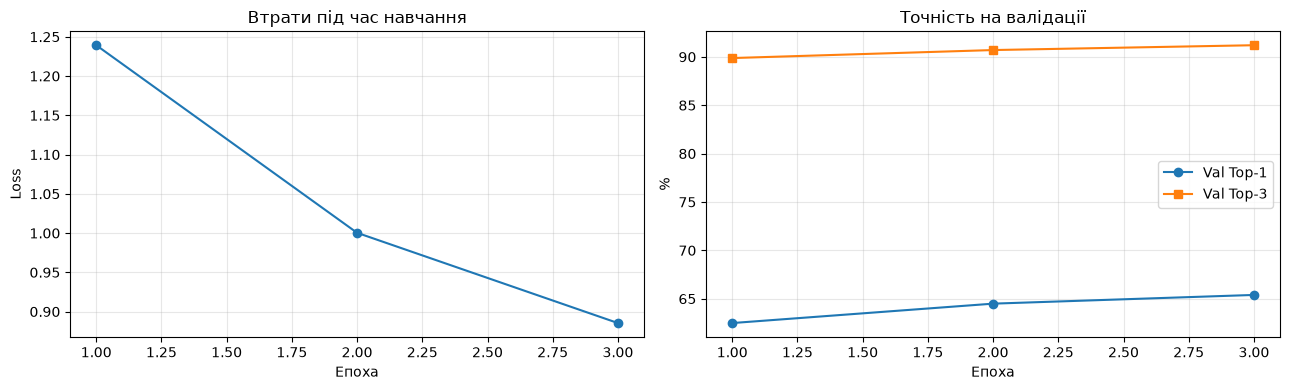

In [15]:
history_df = pd.DataFrame(history)
display(history_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].set_title("Втрати під час навчання")
axes[0].grid(alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["val_top1"], marker="o", label="Val Top-1")
axes[1].plot(history_df["epoch"], history_df["val_top3"], marker="s", label="Val Top-3")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("%")
axes[1].set_title("Точність на валідації")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


In [16]:
print("Фінальні результати Fine-Tuned CLIP:")
print(f"  Top-1 Accuracy:    {top1:.2f}%")
print(f"  Top-3 Accuracy:    {top3:.2f}%")
print(f"  Macro F1:          {macro_f1:.4f}")
print(f"  Balanced Accuracy: {bal_acc:.2f}%")
print(f"  Час навчання:      {train_time_sec:.1f} сек")
print(f"  Пік RAM:           {ram_peak_mb:.1f} MB")

model_path = "clip_wikiart.pth"
torch.save(model.state_dict(), model_path)
model_size_mb = os.path.getsize(model_path) / 2**20
print(f"  Розмір моделі:     {model_size_mb:.2f} MB")

Фінальні результати Fine-Tuned CLIP:
  Top-1 Accuracy:    65.39%
  Top-3 Accuracy:    91.20%
  Macro F1:          0.6482
  Balanced Accuracy: 63.45%
  Час навчання:      7333.6 сек
  Пік RAM:           7.6 MB
  Розмір моделі:     577.28 MB


In [17]:
model.eval()
sample_batch, _ = next(iter(val_loader))
sample_batch = sample_batch.to(device, non_blocking=True)

for _ in range(2):
    with torch.no_grad(), torch.cuda.amp.autocast(enabled=USE_AMP):
        _ = model(sample_batch)

if USE_AMP:
    torch.cuda.synchronize()

t0 = time.perf_counter()
with torch.no_grad(), torch.cuda.amp.autocast(enabled=USE_AMP):
    _ = model(sample_batch)
if USE_AMP:
    torch.cuda.synchronize()

ft_inference_ms = (time.perf_counter() - t0) * 1000.0 / len(sample_batch)
print(f"Fine-Tuned inference: {ft_inference_ms:.4f} мс / зразок (batch={len(sample_batch)})")

Fine-Tuned inference: 25.9529 мс / зразок (batch=64)


In [18]:
BENCHMARK_COLUMNS = [
    "Model",
    "Top1_Acc_%",
    "Top3_Acc_%",
    "Macro_F1",
    "Balanced_Acc_%",
    "Train_Time_s",
    "Inference_ms",
    "RAM_Peak_MB",
    "Model_Size_MB",
]

ft_metrics = {
    "Model": "CLIP ViT-B/32 (Fine-Tuned)",
    "Top1_Acc_%": round(top1, 2),
    "Top3_Acc_%": round(top3, 2),
    "Macro_F1": round(macro_f1, 4),
    "Balanced_Acc_%": round(bal_acc, 2),
    "Train_Time_s": round(train_time_sec, 2),
    "Inference_ms": round(ft_inference_ms, 4),
    "RAM_Peak_MB": round(ram_peak_mb, 2),
    "Model_Size_MB": round(model_size_mb, 2),
}

df_clip = pd.DataFrame([zs_metrics, ft_metrics])[BENCHMARK_COLUMNS]
df_clip.to_csv("benchmark_results_clip.csv", index=False)

print("Збережено: benchmark_results_clip.csv")
display(df_clip)


Збережено: benchmark_results_clip.csv


,Model,Top1_Acc_%,Top3_Acc_%,Macro_F1,Balanced_Acc_%,Train_Time_s,Inference_ms,RAM_Peak_MB,Model_Size_MB
0,CLIP ViT-B/32 (Zero-Shot),26.14,53.38,0.2258,33.38,0.00,25.8920,6.20,577.08
1,CLIP ViT-B/32 (Fine-Tuned),65.39,91.20,0.6482,63.45,7333.56,25.9529,7.57,577.28


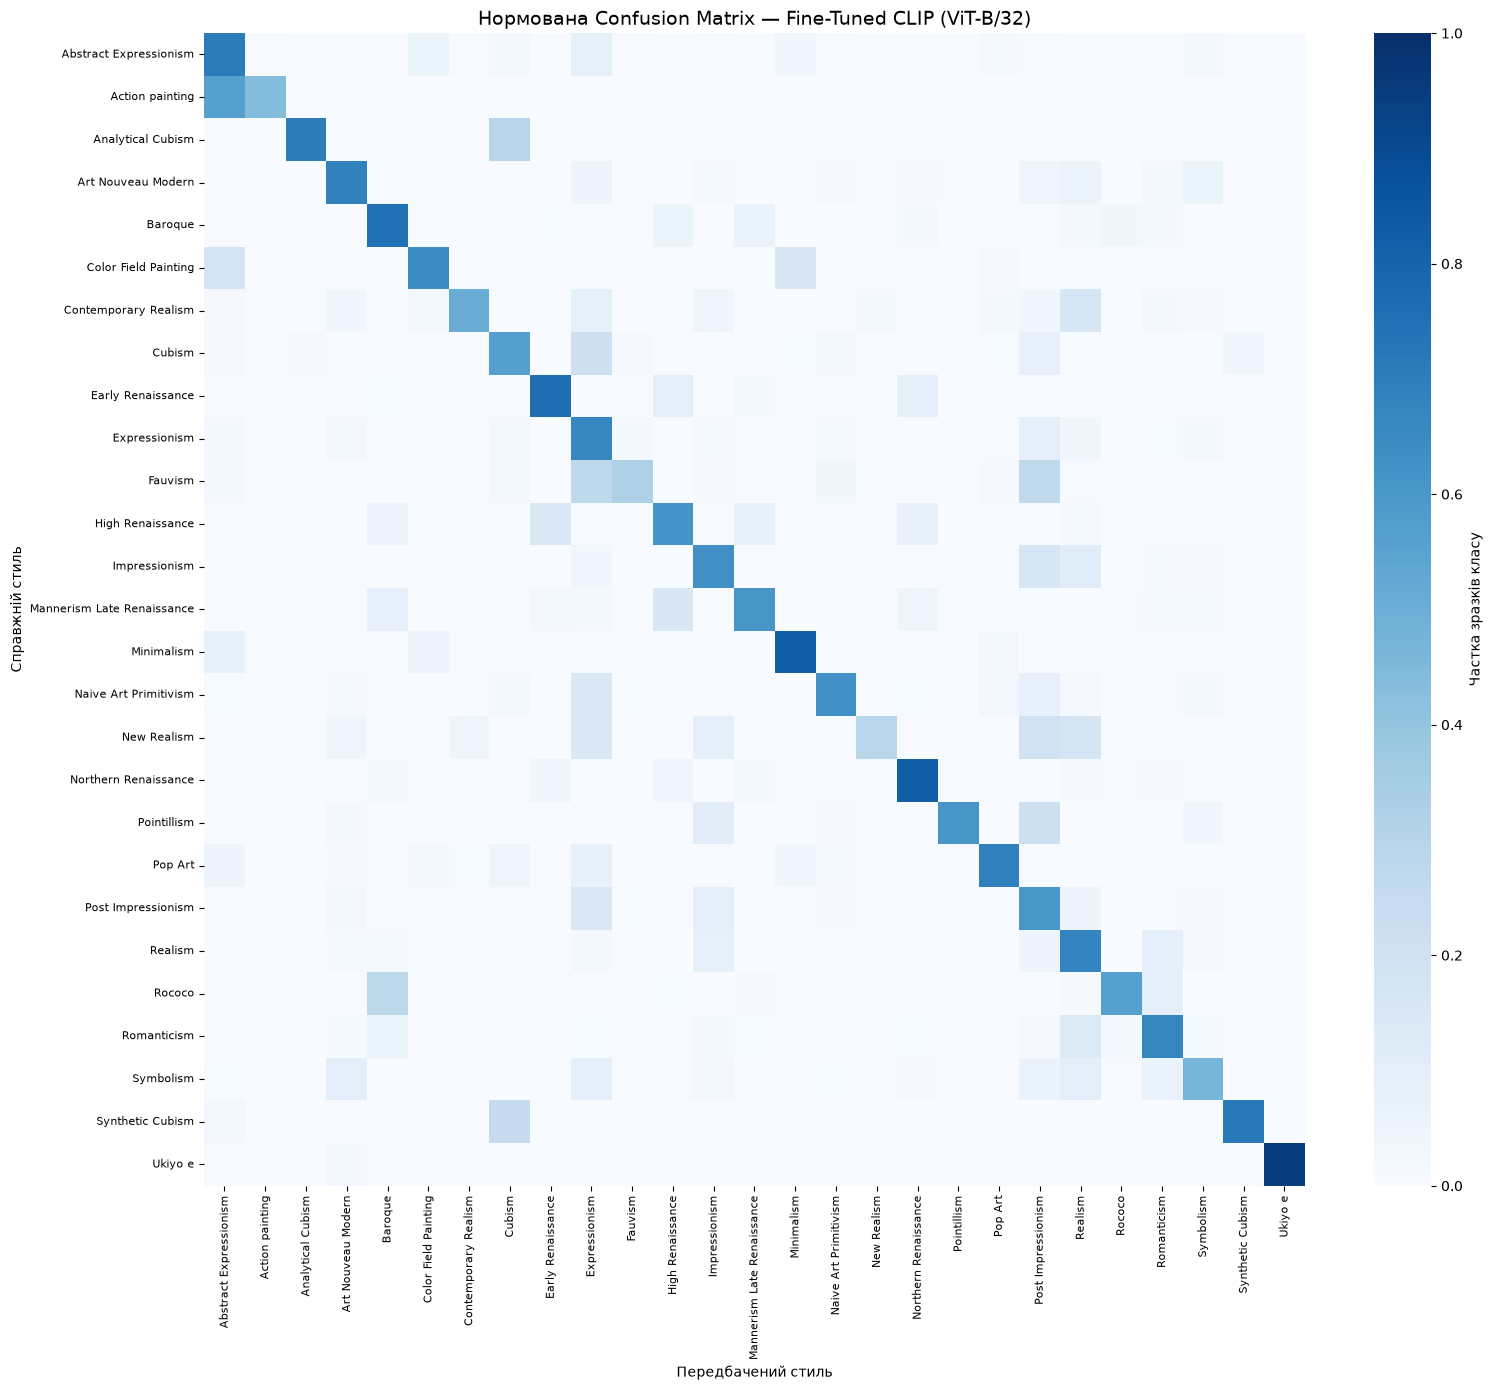

Збережено: confusion_matrix_clip.png


In [19]:
cm = confusion_matrix(y_true, y_pred, normalize="true")

plt.figure(figsize=(16, 14))
sns.heatmap(
    cm,
    cmap="Blues",
    vmin=0.0,
    vmax=1.0,
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Частка зразків класу"},
)
plt.title("Нормована Confusion Matrix — Fine-Tuned CLIP (ViT-B/32)", fontsize=14)
plt.xlabel("Передбачений стиль")
plt.ylabel("Справжній стиль")
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.savefig("confusion_matrix_clip.png", dpi=150, bbox_inches="tight")
plt.show()

print("Збережено: confusion_matrix_clip.png")

## 4. Порівняння всіх трьох етапів

Об'єднуємо бенчмарки:

- `benchmark_results_val.csv` — Етап 1 (класичний ML);
- `benchmark_results_resnet18.csv` — Етап 2 (ResNet-18);
- `benchmark_results_clip.csv` — Етап 3 (CLIP Zero-Shot + Fine-Tuned).

Якщо якогось файлу немає — етап пропускається з попередженням, але ноутбук
не падає. Результат зберігається у `final_models_benchmark_comparison.csv`.


In [20]:
BENCHMARK_COLUMNS = [
    "Model",
    "Top1_Acc_%",
    "Top3_Acc_%",
    "Macro_F1",
    "Balanced_Acc_%",
    "Train_Time_s",
    "Inference_ms",
    "RAM_Peak_MB",
    "Model_Size_MB",
]

benchmark_files = {
    "Етап 1 — Класичний ML": "benchmark_results_val.csv",
    "Етап 2 — ResNet-18": "benchmark_results_resnet18.csv",
    "Етап 3 — CLIP": "benchmark_results_clip.csv",
}

frames = []

for stage, path in benchmark_files.items():
    if not os.path.exists(path):
        print(f"⚠ {path} не знайдено — етап «{stage}» пропущено")
        continue

    df = pd.read_csv(path)
    missing_cols = [c for c in BENCHMARK_COLUMNS if c not in df.columns]
    if missing_cols:
        print(f"⚠ {path}: відсутні колонки {missing_cols} — файл пропущено")
        continue

    df = df[BENCHMARK_COLUMNS].copy()
    df.insert(0, "Stage", stage)
    frames.append(df)
    print(f"✓ {path}: {len(df)} рядків ({stage})")

if not frames:
    raise FileNotFoundError("Не знайдено жодного файлу бенчмарку для об'єднання")

df_final = pd.concat(frames, ignore_index=True)
df_final = df_final.sort_values("Top1_Acc_%", ascending=False).reset_index(drop=True)

df_final.to_csv("final_models_benchmark_comparison.csv", index=False)
print("\nЗбережено: final_models_benchmark_comparison.csv")
display(df_final)


✓ benchmark_results_val.csv: 7 рядків (Етап 1 — Класичний ML)
✓ benchmark_results_resnet18.csv: 1 рядків (Етап 2 — ResNet-18)
✓ benchmark_results_clip.csv: 2 рядків (Етап 3 — CLIP)

Збережено: final_models_benchmark_comparison.csv


,Stage,Model,Top1_Acc_%,Top3_Acc_%,Macro_F1,Balanced_Acc_%,Train_Time_s,Inference_ms,RAM_Peak_MB,Model_Size_MB
0,Етап 3 — CLIP,CLIP ViT-B/32 (Fine-Tuned),65.39,91.20,0.6482,63.45,7333.56,25.9529,7.57,577.28
1,Етап 2 — ResNet-18,ResNet-18 (Deep Learning),58.15,85.36,0.5673,53.75,4608.43,0.1074,20.16,42.76
2,Етап 1 — Класичний ML,Ensemble (GBDT 40% + ET 60%),38.59,66.12,0.3120,31.08,585.00,0.1399,556.88,157.25
3,Етап 1 — Класичний ML,"Tuned HistGradientBoosting (Full 651, Smoothed)",38.18,65.99,0.3071,29.29,559.35,0.0924,556.88,5.98
4,Етап 1 — Класичний ML,"ExtraTrees Classifier (Full 651, Balanced)",31.05,57.12,0.2493,30.44,25.65,0.0475,164.09,151.27
5,Етап 1 — Класичний ML,"Logistic Regression (Smoothed, PCA-128)",27.61,53.30,0.1339,14.02,4.39,0.0007,25.80,0.03
6,Етап 1 — Класичний ML,"Logistic Regression (Unweighted, PCA-128)",26.91,52.51,0.1071,11.15,9.25,0.0006,25.37,0.03
7,Етап 1 — Класичний ML,"HistGradientBoosting (Balanced, PCA-128)",26.29,52.11,0.2129,24.83,74.31,0.0290,111.47,1.77
8,Етап 3 — CLIP,CLIP ViT-B/32 (Zero-Shot),26.14,53.38,0.2258,33.38,0.00,25.8920,6.20,577.08
9,Етап 1 — Класичний ML,"SGD (Balanced, PCA-128)",19.01,39.25,0.1040,16.10,5.42,0.0008,2911.79,0.03


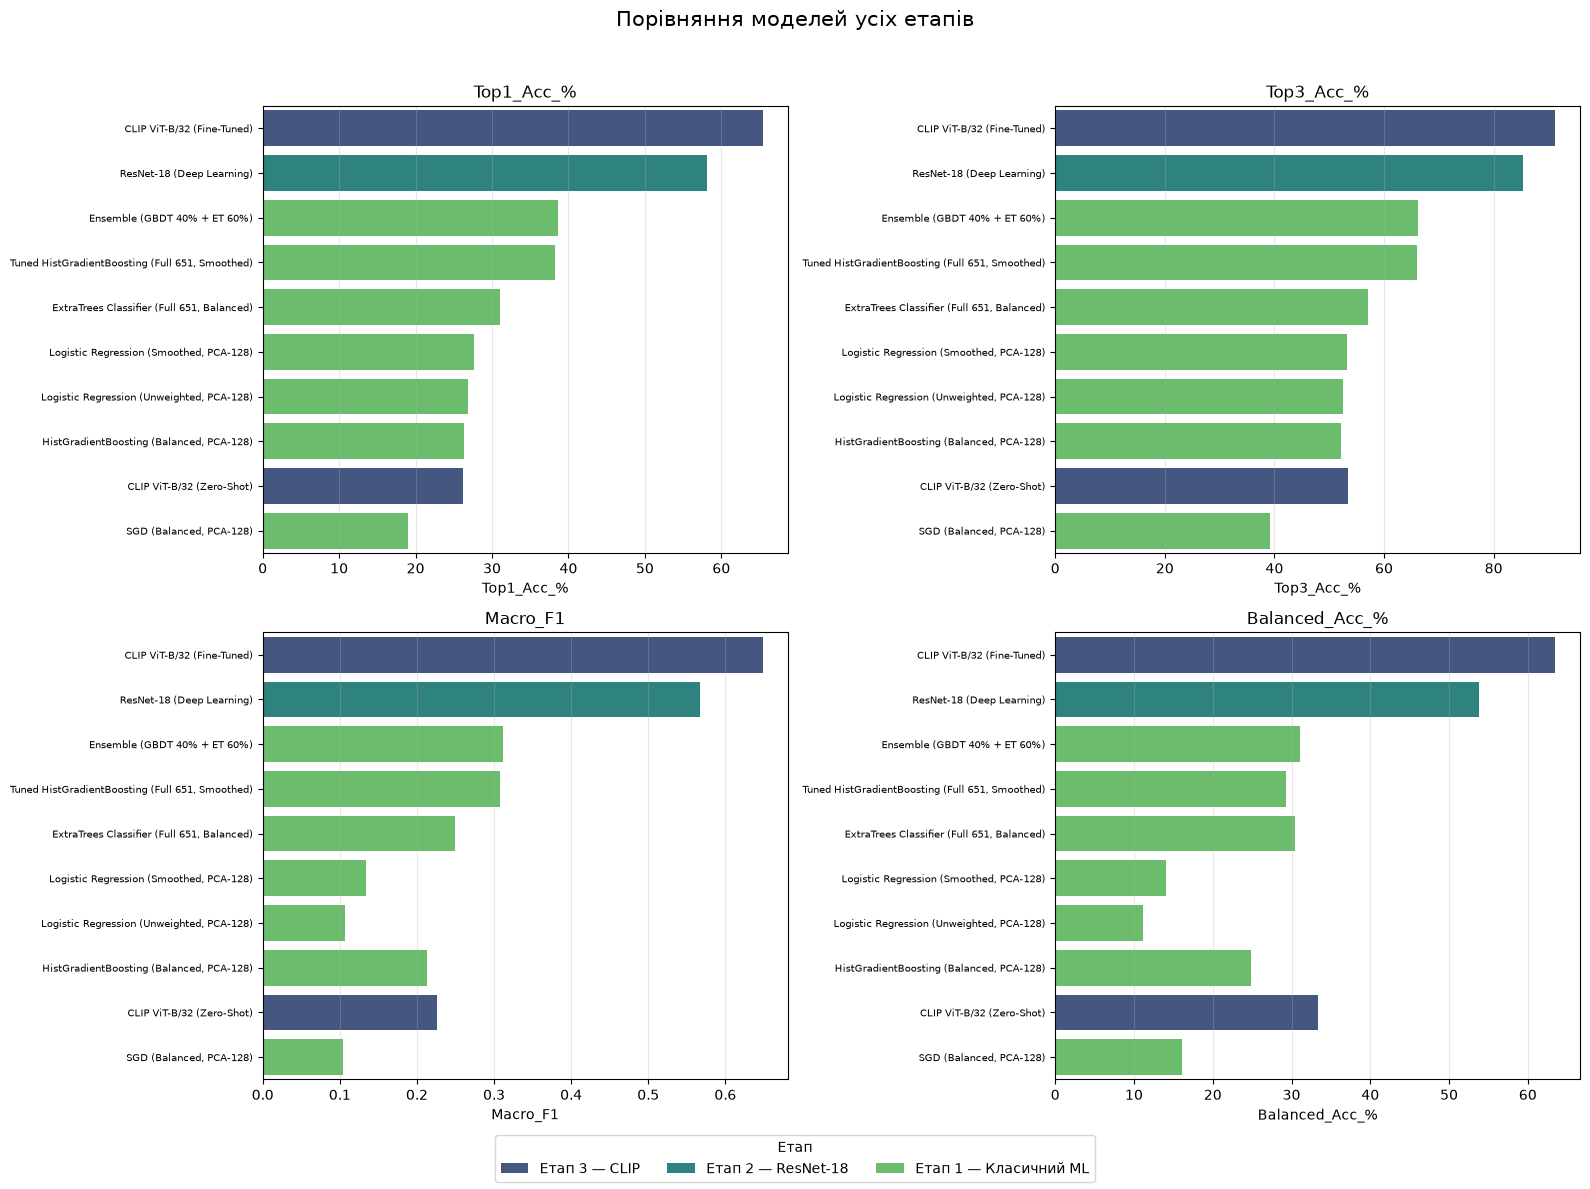

Збережено: final_benchmark_comparison.png


In [21]:
# Горизонтальні bar-chart'и: зручніше для довгих назв моделей
metrics_to_plot = ["Top1_Acc_%", "Top3_Acc_%", "Macro_F1", "Balanced_Acc_%"]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, metric in zip(axes.ravel(), metrics_to_plot):
    sns.barplot(
        data=df_final,
        y="Model",
        x=metric,
        hue="Stage",
        dodge=False,
        palette="viridis",
        ax=ax,
    )
    ax.set_title(metric, fontsize=12)
    ax.set_xlabel(metric)
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="y", labelsize=7)
    if ax.get_legend() is not None:
        ax.get_legend().remove()

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, title="Етап")
fig.suptitle("Порівняння моделей усіх етапів", fontsize=15)

plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.savefig("final_benchmark_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("Збережено: final_benchmark_comparison.png")


In [22]:
# Короткий динамічний підсумок за фактичними результатами
best_row = df_final.loc[df_final["Top1_Acc_%"].idxmax()]

print("Ключові спостереження:")
print(f"  • Найкраща модель: {best_row['Model']} — Top-1 {best_row['Top1_Acc_%']:.2f}%")

zs_row = df_final[df_final["Model"] == "CLIP ViT-B/32 (Zero-Shot)"]
ft_row = df_final[df_final["Model"] == "CLIP ViT-B/32 (Fine-Tuned)"]

if not zs_row.empty and not ft_row.empty:
    zs_top1_val = float(zs_row.iloc[0]["Top1_Acc_%"])
    zs_top3_val = float(zs_row.iloc[0]["Top3_Acc_%"])
    ft_top1_val = float(ft_row.iloc[0]["Top1_Acc_%"])
    print(f"  • Zero-Shot без навчання: Top-1 {zs_top1_val:.2f}%, Top-3 {zs_top3_val:.2f}%")
    print(
        f"  • Fine-tuning: {zs_top1_val:.2f}% → {ft_top1_val:.2f}% "
        f"(+{ft_top1_val - zs_top1_val:.2f} в.п.)"
    )

clip_rows = df_final[df_final["Model"].str.contains("CLIP")]
if not clip_rows.empty:
    print(f"  • Розмір CLIP на диску: {clip_rows['Model_Size_MB'].max():.1f} MB")


Ключові спостереження:
  • Найкраща модель: CLIP ViT-B/32 (Fine-Tuned) — Top-1 65.39%
  • Zero-Shot без навчання: Top-1 26.14%, Top-3 53.38%
  • Fine-tuning: 26.14% → 65.39% (+39.25 в.п.)
  • Розмір CLIP на диску: 577.3 MB
